In [30]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from src import Questions
import matplotlib.patches as mpatches
from scipy.stats import ttest_ind
from itertools import combinations

In [31]:
# definitions
models = [
    "gpt_4o",
    "llama31_70B_Inst",
    "Qwen25_72B_Inst",
    "llama31_8B_Inst",
    "Qwen25_7B_Inst",
    "llama32_1B_Inst",
    "Qwen25_1dot5B_Inst"
]
task_types = [
    'mt_and_summarization',
    'syntaxes',
    'knowledge_and_reasoning',
    'semantics',
    'qa_extraction'
]
demography_profiles = [
    "employment_sector",
    "race",
    "education",
    "sex",
    "age",
    "language",
    "nationality_group"
]
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"

EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]

In [32]:
# creating a dataframe of all of the annotator profiles
questions = Questions().get_questions()

In [33]:
stacked_model_df = []
for model in models:
    model_specific_scores = []
    for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
        annobj_for_df = {}
        annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
        with open(annotator_filepath, "r") as ao:
            annotator_object = json.load(ao)
        
        annobj_for_df["id"] = annotator_object["id"]
        annobj_for_df.update(**annotator_object["profile"])
        
        for i, (question, scores_for_question) in enumerate(annotator_object["answers"].items()):
            if not scores_for_question["answer"]:
                continue
            else:
                for qdi, scores in scores_for_question["downstream_scores"][model].items():
                    annobj_for_df[qdi] = list(scores.values())[0]
        model_specific_scores.append(annobj_for_df)
    score_df = pd.DataFrame(model_specific_scores)
    exclude_cols = ["id"] + demography_profiles
    task_cols = [col for col in score_df.columns if col not in exclude_cols]
    stacked_model_df.append(score_df[task_cols])

def get_min_max_from_stacked_df(stacked_model_df):
    # Stack all DataFrames into one
    combined_df = pd.concat(stacked_model_df, ignore_index=True)

    # Compute min and max for each column
    return {
        col: {
            'min': combined_df[col].min(),
            'max': combined_df[col].max()
        }
        for col in combined_df.columns
    }

universal_scoredf_minmax = get_min_max_from_stacked_df(stacked_model_df)

In [34]:
def calculate_diversity_score(list_of_values):
    if len(list_of_values) < 2:
        return 0  # No diversity if less than 2 elements
    
    total = 0
    count = 0
    for i in range(len(list_of_values)):
        for j in range(i + 1, len(list_of_values)):
            total += abs(list_of_values[i] - list_of_values[j])
            count += 1
    return total / count

model_diversity_scores = []
highlight_data = {
    "gpt_4o" : {},
    "llama31_70B_Inst" : {},
    "Qwen25_72B_Inst" : {}
}

for model in models:
    model_specific_scores = []
    for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
        annobj_for_df = {}
        annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
        with open(annotator_filepath, "r") as ao:
            annotator_object = json.load(ao)
        
        annobj_for_df["id"] = annotator_object["id"]
        annobj_for_df.update(**annotator_object["profile"])
        
        for i, (question, scores_for_question) in enumerate(annotator_object["answers"].items()):
            if not scores_for_question["answer"]:
                continue
            else:
                for qdi, scores in scores_for_question["downstream_scores"][model].items():
                    annobj_for_df[qdi] = list(scores.values())[0]
        model_specific_scores.append(annobj_for_df)
    score_df = pd.DataFrame(model_specific_scores)
    exclude_cols = ["id"] + demography_profiles
    task_cols = [col for col in score_df.columns if col not in exclude_cols]
    for tcol in task_cols:
        min_val = universal_scoredf_minmax[tcol]['min']
        max_val = universal_scoredf_minmax[tcol]['max']
        score_df[tcol] = (score_df[tcol] - min_val) / (max_val - min_val)
    
    demography_profile_means = {}
    for dp in demography_profiles:
        if model in highlight_data and dp not in highlight_data[model]:
            highlight_data[model][dp] = {}

        demo_avgs = {}
        demo_grouped = score_df.groupby([dp])
        for demo_name, group in demo_grouped:
            # implement here for exceptions
            if dp == "employment_sector":
                group = group[group["language"] == "L1"]
            elif dp == "education":
                group = group[group["language"] == "L1"]
            elif dp == "sex":
                group = group[group["language"] == "L1"]
                
            elif(demo_name == "Black"):
                group = group[group["language"] == "L1"]
            elif(demo_name == "White"):
                group = group[group["language"] == "L1"]
            # implement here for exceptions
            task_scores = []
            for tc in task_cols:
                if not any(tc.startswith(prefix) for prefix in EXCLUDED_SCORES):
                    task_scores.append(group[tc].mean())
            task_average = np.nanmean(task_scores)
            demo_avgs[demo_name[0]] = task_average

            if(model in highlight_data):
                highlight_data[model][dp][demo_name[0]] = task_average
        demography_profile_means[dp] = demo_avgs
    
    diversity_scores = {}
    for dpm_k, dpm_v in demography_profile_means.items():
        diversity_scores[dpm_k] = calculate_diversity_score(list(dpm_v.values()))
    
    model_diversity_scores.append({
        "model" : model,
        **diversity_scores
    })

In [35]:
model_diversity_df = pd.DataFrame(model_diversity_scores)
model_diversity_df = model_diversity_df.map(
    lambda x: f"{x * 100:.1f}%" if isinstance(x, float) else x
)
model_diversity_df

,model,employment_sector,race,education,sex,age,language,nationality_group
0,gpt_4o,1.0%,0.3%,0.9%,0.6%,0.4%,0.0%,0.7%
1,llama31_70B_Inst,0.5%,0.5%,0.9%,0.0%,0.4%,0.5%,0.7%
2,Qwen25_72B_Inst,2.0%,0.5%,0.8%,0.7%,0.7%,0.5%,1.1%
3,llama31_8B_Inst,2.0%,0.8%,1.6%,1.3%,0.4%,1.1%,0.8%
4,Qwen25_7B_Inst,0.5%,0.1%,0.2%,0.6%,0.3%,0.2%,0.3%
5,llama32_1B_Inst,1.7%,0.2%,1.0%,0.4%,0.3%,0.1%,0.4%
6,Qwen25_1dot5B_Inst,1.3%,0.4%,0.7%,0.6%,0.3%,0.1%,0.7%


In [43]:
escaped_df = model_diversity_df.map(
    lambda x: x.replace('_', r'\_').replace('%', r'\%') if isinstance(x, str) else x
)

print(escaped_df.to_latex(index=False))

\begin{tabular}{llllllll}
\toprule
model & employment_sector & race & education & sex & age & language & nationality_group \\
\midrule
gpt\_4o & 1.0\% & 0.3\% & 0.9\% & 0.6\% & 0.4\% & 0.0\% & 0.7\% \\
llama31\_70B\_Inst & 0.5\% & 0.5\% & 0.9\% & 0.0\% & 0.4\% & 0.5\% & 0.7\% \\
Qwen25\_72B\_Inst & 2.0\% & 0.5\% & 0.8\% & 0.7\% & 0.7\% & 0.5\% & 1.1\% \\
llama31\_8B\_Inst & 2.0\% & 0.8\% & 1.6\% & 1.3\% & 0.4\% & 1.1\% & 0.8\% \\
Qwen25\_7B\_Inst & 0.5\% & 0.1\% & 0.2\% & 0.6\% & 0.3\% & 0.2\% & 0.3\% \\
llama32\_1B\_Inst & 1.7\% & 0.2\% & 1.0\% & 0.4\% & 0.3\% & 0.1\% & 0.4\% \\
Qwen25\_1dot5B\_Inst & 1.3\% & 0.4\% & 0.7\% & 0.6\% & 0.3\% & 0.1\% & 0.7\% \\
\bottomrule
\end{tabular}



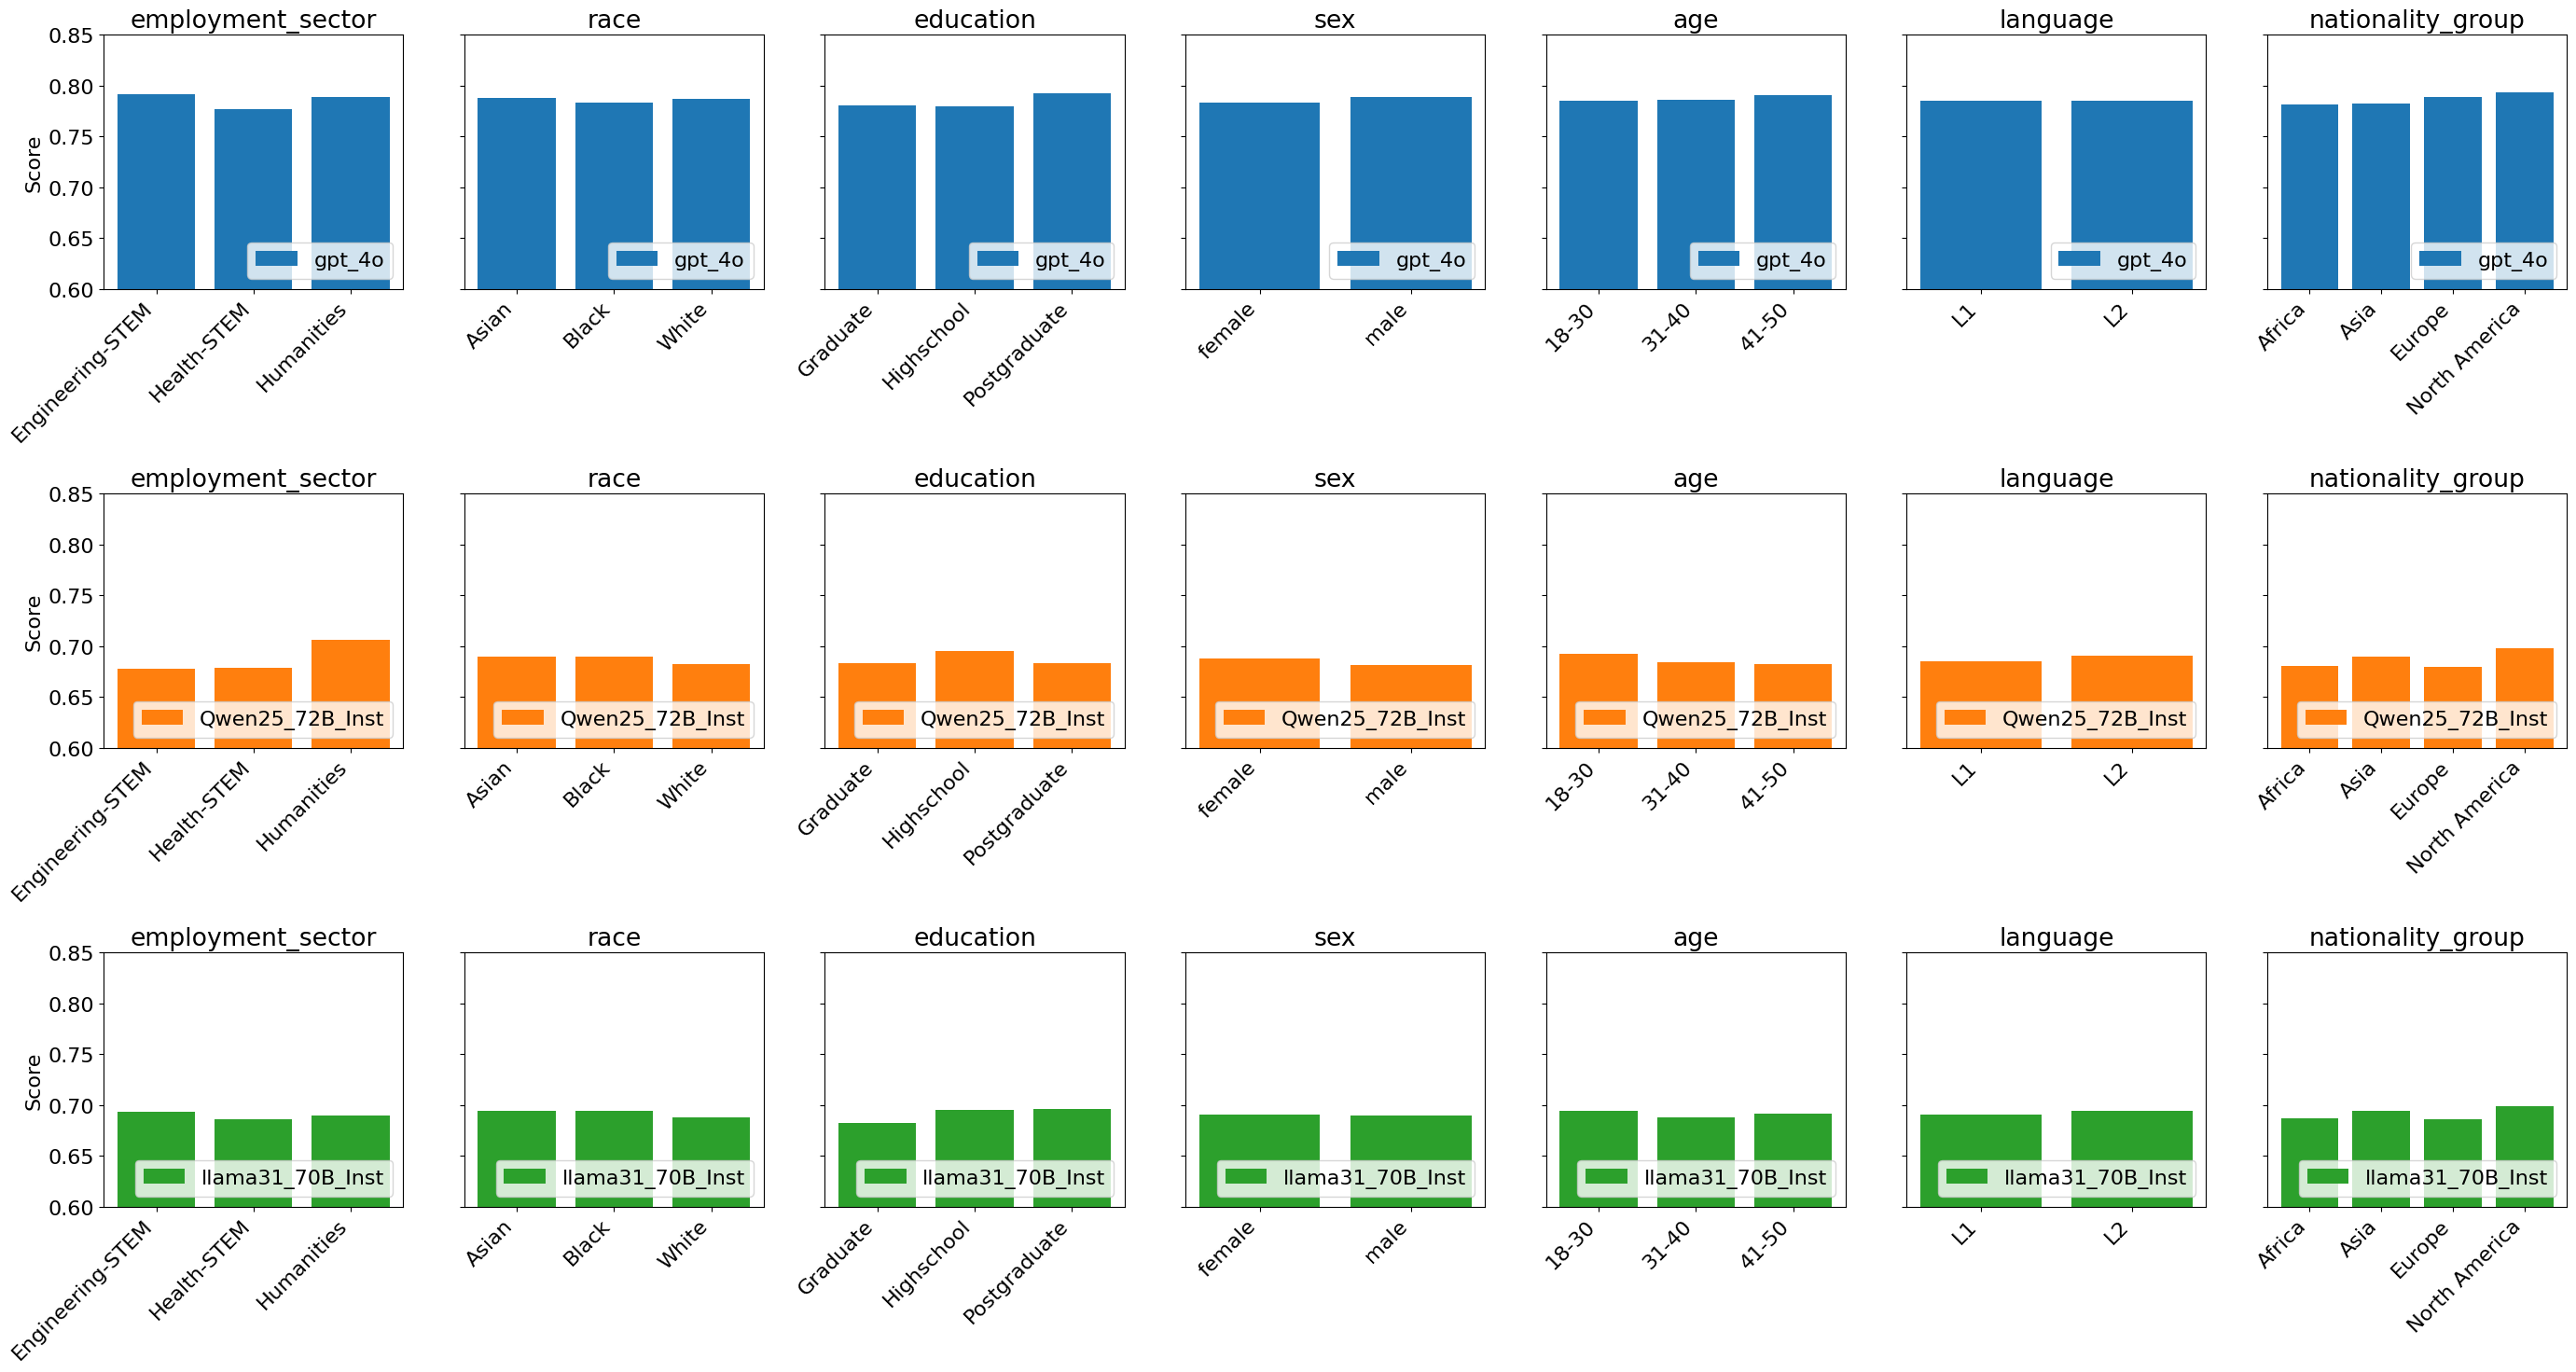

In [47]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 16})

models = list(highlight_data.keys())
categories = list(highlight_data[models[0]].keys())

fig, axes = plt.subplots(len(models), len(categories), figsize=(4 * len(categories), 15), sharey=True)

for modelname in models:
    for idx, category in enumerate(categories):
        keys = list(highlight_data[models[0]][category].keys())
        if modelname == "gpt_4o":
            values = [highlight_data['gpt_4o'][category][k] for k in keys]
            color = "tab:blue"
            ax = axes[0][idx]
        elif modelname == "Qwen25_72B_Inst":
            values = [highlight_data['Qwen25_72B_Inst'][category][k] for k in keys]
            color = "tab:orange"
            ax = axes[1][idx]
        else:
            values = [highlight_data['llama31_70B_Inst'][category][k] for k in keys]
            color = "tab:green"
            ax = axes[2][idx]
        
        x = range(len(keys))
        ax.bar(x, values, label=modelname, color=color)
        # ax.bar([i + width/2 for i in x], llama_vals, width=width, label='llama31_70B_Inst')
        ax.set_xticks(x)
        ax.set_xticklabels(keys, rotation=45, ha='right')
        ax.set_title(category)
        ax.set_ylim(0.6, 0.85)
        if idx == 0:
            ax.set_ylabel("Score")

        ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [48]:
mt_imperative = []
mt_declarative = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as ao:
        annotator_object = json.load(ao)
        mt_answer = annotator_object["answers"]["A translation system is an AI model or software system designed to automatically convert text from one language to another, facilitating communication between speakers of different languages.<b>Example</b><i>Arabic text</i>: \"انا احب الايفون\" <i>French translation</i>: \"J\'adore l\'iPhone\"You are using a language model like ChatGPT to translate a text [TEXT] in [LANGUAGE1] to [LANGUAGE2]. How would you phrase your request to the language model? <b>Your response must include the placeholder [TEXT] and [LANGUAGE2].</b> The placeholder [LANGUAGE1] is optional."]
        if(mt_answer["answer"]):
            if():
                mt_declarative.append({
                    "answer" : mt_answer["answer"],
                    "gpt" : mt_answer["downstream_scores"]["gpt_4o"],
                    "llama" : mt_answer["downstream_scores"]["llama31_70B_Inst"],
                })
            elif(mt_answer["sentence_type"] == "imperative"):
                mt_imperative.append({
                    "answer" : mt_answer["answer"],
                    "gpt" : mt_answer["downstream_scores"]["gpt_4o"],
                    "llama" : mt_answer["downstream_scores"]["llama31_70B_Inst"],
                })

In [49]:
mt_declarative

[]

In [40]:
mt_imperative[55:57]

[{'answer': 'Translate "[TEXT]" to [LANGUAGE2]',
  'gpt': {'2_14': {'Machine Translation-hau_Latn-2_14-bleu_score': 18.777225643937577},
   '2_13': {'Machine Translation-amh_Ethi-2_13-bleu_score': 4.7916369087816655},
   '2_12': {'Machine Translation-uig_Arab-2_12-bleu_score': 4.125960264282456},
   '2_11': {'Machine Translation-bug_Latn-2_11-bleu_score': 2.4512773618310533},
   '2_10': {'Machine Translation-ace_Latn-2_10-bleu_score': 2.177052020558627},
   '2_9': {'Machine Translation-tur_Latn-2_9-bleu_score': 24.86070473885477},
   '2_8': {'Machine Translation-arb_Arab-2_8-bleu_score': 25.971608277545656},
   '2_7': {'Machine Translation-hin_Deva-2_7-bleu_score': 29.62514767093571},
   '2_6': {'Machine Translation-tgl_Latn-2_6-bleu_score': 35.36615418340749},
   '2_4': {'Machine Translation-jpn_Jpan-2_4-bleu_score': 4.580730742072266},
   '2_3': {'Machine Translation-deu_Latn-2_3-bleu_score': 37.97086028830058},
   '2_2': {'Machine Translation-spa_Latn-2_2-bleu_score': 27.88963818648

In [41]:
REJECT_THRESHOLD = 0.05
EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]

def pairwise_p_values(data_dict):
    results = {}
    for (key1, values1), (key2, values2) in combinations(data_dict.items(), 2):
        stat, p = ttest_ind(values1, values2, equal_var=False)
        results[f"{key1} ---- {key2}"] = p
    return results

model_Ho_rejects = {}
for model in models:
    model_specific_scores = []
    for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
        annobj_for_df = {}
        annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
        with open(annotator_filepath, "r") as ao:
            annotator_object = json.load(ao)
        
        annobj_for_df["id"] = annotator_object["id"]
        annobj_for_df.update(**annotator_object["profile"])
        
        for i, (question, scores_for_question) in enumerate(annotator_object["answers"].items()):
            if not scores_for_question["answer"]:
                continue
            else:
                for qdi, scores in scores_for_question["downstream_scores"][model].items():
                    annobj_for_df[qdi] = list(scores.values())[0]
        model_specific_scores.append(annobj_for_df)
    score_df = pd.DataFrame(model_specific_scores)
    exclude_cols = ["id"] + demography_profiles
    task_cols = [col for col in score_df.columns if col not in exclude_cols]
    
    # # no need to normalize anymore i think
    # # score_df[task_cols] = (score_df[task_cols] - score_df[task_cols].min()) / (score_df[task_cols].max() - score_df[task_cols].min())
    
    demography_profile_fullscores = {}
    for dp in demography_profiles:
        demo_fulllist = {}
        demo_grouped = score_df.groupby([dp])
        for demo_name, group in demo_grouped:
            # implement here for exceptions
            if dp == "employment_sector":
                group = group[group["language"] == "L1"]
            elif dp == "education":
                group = group[group["language"] == "L1"]
            elif dp == "sex":
                group = group[group["language"] == "L1"]
                
            elif(demo_name == "Black"):
                group = group[group["language"] == "L1"]
            elif(demo_name == "White"):
                group = group[group["language"] == "L1"]
            # implement here for exceptions
            task_scores = []
            for tc in task_cols:
                if not any(tc.startswith(prefix) for prefix in EXCLUDED_SCORES):
                    task_scores += group[tc].dropna().to_list()
            demo_fulllist[demo_name[0]] = task_scores
        demography_profile_fullscores[dp] = demo_fulllist
    
    # Ho_rejects = {}
    # for dpk in demography_profile_fullscores:
    #     p_values_of_pairs = pairwise_p_values(demography_profile_fullscores[dpk])
    #     subHo_rejects = {}
    #     for pairname, pval in p_values_of_pairs.items():
    #         if pval < REJECT_THRESHOLD:
    #             subHo_rejects[pairname] = pval
    #     Ho_rejects[dpk] = subHo_rejects

    # model_Ho_rejects[model] = Ho_rejects

In [50]:
print(json.dumps(model_Ho_rejects["gpt_4o"], indent=4))

KeyError: 'gpt_4o'

In [ ]:
score_df

,id,employment_sector,race,education,sex,age,language,nationality_group,0_0,1_0,...,27_5,27_4,27_3,27_2,27_1,27_0,5_0,7_0,10_0,28_0
0,34,Humanities,Black,Postgraduate,female,31-40,None,North America,0.699965,0.482490,...,0.643892,0.651948,0.965152,0.639541,0.659281,0.692796,NaN,NaN,NaN,NaN
1,63,Engineering-STEM,White,Postgraduate,male,31-40,L1,Europe,0.512191,0.538021,...,0.699922,0.808592,0.774446,0.635017,0.871573,0.778577,1.0,1.0,0.750,0.35
2,75,Health-STEM,White,Graduate,female,31-40,None,Europe,0.442910,0.611143,...,0.867162,0.914363,0.815313,0.807860,0.872641,0.777485,0.0,0.5,0.750,0.60
3,22,Engineering-STEM,Black,Postgraduate,female,18-30,L1,Africa,0.621525,0.629431,...,0.660315,0.666339,0.822756,0.680339,0.664472,0.717848,1.0,1.0,0.750,0.50
4,59,Health-STEM,White,Graduate,female,31-40,L1,Europe,NaN,0.482095,...,0.063968,0.056896,0.101569,0.068121,0.132663,0.068852,1.0,0.5,0.750,0.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,37,Humanities,Asian,Highschool,female,18-30,L2,Asia,0.745335,0.833589,...,0.753054,0.908230,0.876377,0.764810,0.920090,0.867264,1.0,0.5,0.875,0.15
95,60,Health-STEM,Asian,Postgraduate,male,41-50,L1,Europe,0.486219,NaN,...,0.353055,0.315182,0.596345,0.327362,0.285671,0.390637,1.0,NaN,0.750,NaN
96,76,Engineering-STEM,White,Postgraduate,male,31-40,None,Africa,0.583487,0.667011,...,0.388227,0.366256,0.638399,0.416455,0.432725,0.466778,NaN,1.0,0.750,0.65
97,99,Engineering-STEM,Black,Postgraduate,female,41-50,None,North America,0.628350,0.406782,...,0.874587,0.944871,0.970943,0.926657,0.892889,0.883675,1.0,NaN,0.875,0.85
